# Regular time series
`RegularTs` holds values, the time of the first value and metadata. The interval comes from the E part of the pathname.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # use the in-place build of the repo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyheclib as phl

plt.style.use('ggplot')
# restart the kernel if this is not the version / location you expect
print('pyheclib', phl.__version__, 'from', os.path.dirname(phl.__file__))

if os.path.exists('regular_ts.dss'):
    os.remove('regular_ts.dss')
dss_file = phl.open('regular_ts.dss')
dss_file

pyheclib 0.4.0 from /Users/nzahasan/Development/pyheclib/pyheclib


<DssFile open 'regular_ts.dss'>

## Create from values

In [2]:
precip = phl.RegularTs('/DEMO/GAGE/PRECIP//1DAY/OBS/', values=[0.0, 12.5, 48.0, 3.1, 0.0],
                       start='2020-01-14', unit='MM', type='PER-CUM')
precip.interval, precip.times

('1DAY',
 DatetimeIndex(['2020-01-14', '2020-01-15', '2020-01-16', '2020-01-17',
                '2020-01-18'],
               dtype='datetime64[ns]', name='Time', freq='D'))

In [3]:
dss_file.write(precip)
precip_read = dss_file.read(precip.path)
assert isinstance(precip_read, phl.RegularTs)
np.testing.assert_allclose(precip_read.values, precip.values)
assert precip_read.times.equals(precip.times)
precip_read.to_series()

Time
2020-01-14     0.0
2020-01-15    12.5
2020-01-16    48.0
2020-01-17     3.1
2020-01-18     0.0
Freq: D, Name: PRECIP, dtype: float64

## Create from a pandas Series
Hourly flow over 3 months (several DSS monthly blocks) with a gap of missing values.

In [4]:
hours = pd.date_range('2020-01-01 01:00', '2020-04-01 00:00', freq='h')
flow = pd.Series(100 + 40*np.sin(np.arange(hours.size)/24/7*2*np.pi)
                 + np.random.default_rng(0).normal(0, 3, hours.size), index=hours)
flow.iloc[500:520] = np.nan

rts = phl.RegularTs.from_series('/DEMO/OUTLET/FLOW//1HOUR/OBS/', flow, unit='CFS', type='INST-VAL')
dss_file.write(rts)

rts_read = dss_file.read('/DEMO/OUTLET/FLOW//1HOUR/OBS/')
flow_read = rts_read.to_series()
assert flow_read.index.equals(flow.index.rename('Time'))
np.testing.assert_allclose(flow_read.values, flow.values)
assert flow_read.isna().sum() == 20
rts_read.unit, rts_read.type, rts_read.interval, rts_read.start, rts_read.values.size

('CFS', 'INST-VAL', '1HOUR', Timestamp('2020-01-01 01:00:00'), 2184)

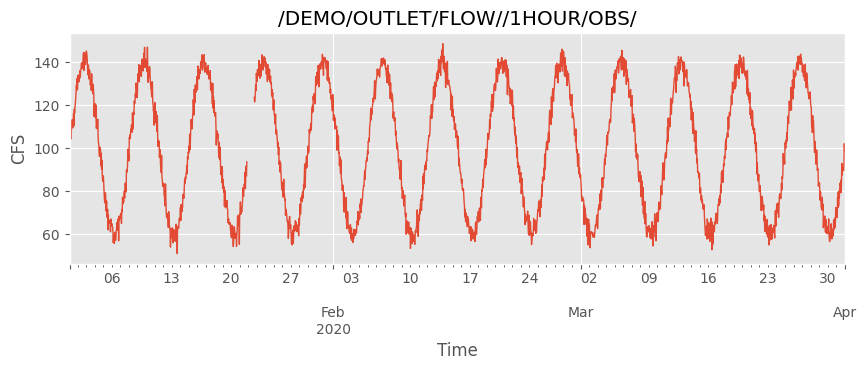

In [5]:
ax = flow_read.plot(figsize=(10, 3), lw=1, title=str(rts_read.path))
ax.set_ylabel(rts_read.unit);

## Time window

In [6]:
win = dss_file.read('/DEMO/OUTLET/FLOW//1HOUR/OBS/', start='2020-02-10 00:00', end='2020-02-10 05:00')
assert win.values.size == 6
np.testing.assert_allclose(win.values, flow['2020-02-10 00:00':'2020-02-10 05:00'].values)
win.to_series()

Time
2020-02-10 00:00:00    63.065681
2020-02-10 01:00:00    53.365170
2020-02-10 02:00:00    59.675466
2020-02-10 03:00:00    62.725612
2020-02-10 04:00:00    59.166447
2020-02-10 05:00:00    55.531037
Freq: h, Name: FLOW, dtype: float64

## Overwrite part of a series
Writing replaces values in the time span of the new record.

In [7]:
dss_file.write(phl.RegularTs('/DEMO/GAGE/PRECIP//1DAY/OBS/', [99.0], start='2020-01-16', unit='MM', type='PER-CUM'))
updated = dss_file.read('/DEMO/GAGE/PRECIP//1DAY/OBS/').to_series()
assert updated.tolist() == [0.0, 12.5, 99.0, 3.1, 0.0]
updated

Time
2020-01-14     0.0
2020-01-15    12.5
2020-01-16    99.0
2020-01-17     3.1
2020-01-18     0.0
Freq: D, Name: PRECIP, dtype: float64

In [8]:
dss_file.close()
print('all checks passed')

all checks passed
